In [6]:
import numpy as np
import matplotlib.pyplot as plt
from abc import ABC, abstractmethod


class BohmStrategy(ABC):

    @abstractmethod
    def resolve(self, **kwargs):
        pass


class Bohm1DStrategy(BohmStrategy):

    def resolve(
        self,
        L=100,
        T=10,
        dx=1,
        dt=0.1,
        D=0.1,
        v=1,
        C0=100,
        source=0
    ):

        nx = int(L / dx) + 1
        nt = int(T / dt) + 1

        x = np.linspace(0, L, nx)

        C = np.zeros(nx)
        C[source] = C0

        alpha = D * dt / dx**2
        beta = v * dt / dx

        if alpha + beta / 2 > 0.5:
            raise ValueError(
                "Esquema inestable. Reduce dt o aumenta dx."
            )

        for _ in range(nt):

            C_new = np.zeros(nx)

            C_new[1:-1] = (
                C[1:-1]
                + alpha * (
                    C[2:]
                    - 2 * C[1:-1]
                    + C[:-2]
                )
                - beta * (
                    C[1:-1]
                    - C[:-2]
                )
            )

            C_new[0] = C0

            C = C_new

        return {
            "x": x,
            "concentration": C,
            "alpha": alpha,
            "beta": beta
        }


class Bohm3DStrategy(BohmStrategy):

    def resolve(
        self,
        L=100,
        T=10,
        dx=1,
        dy=1,
        dz=1,
        dt=0.05,
        D=0.1,
        vx=1,
        vy=0.5,
        vz=0.1,
        C0=100
    ):

        nx = int(L / dx) + 1
        ny = int(L / dy) + 1
        nz = int(L / dz) + 1

        nt = int(T / dt) + 1

        C = np.zeros((nx, ny, nz))

        C[0, :, :] = C0

        alpha = D * dt / dx**2

        beta_x = vx * dt / dx
        beta_y = vy * dt / dy
        beta_z = vz * dt / dz

        for _ in range(nt):

            C_new = C.copy()

            C_new[1:-1, 1:-1, 1:-1] = (
                C[1:-1, 1:-1, 1:-1]

                + alpha * (
                    C[2:, 1:-1, 1:-1]
                    - 2 * C[1:-1, 1:-1, 1:-1]
                    + C[:-2, 1:-1, 1:-1]

                    + C[1:-1, 2:, 1:-1]
                    - 2 * C[1:-1, 1:-1, 1:-1]
                    + C[1:-1, :-2, 1:-1]

                    + C[1:-1, 1:-1, 2:]
                    - 2 * C[1:-1, 1:-1, 1:-1]
                    + C[1:-1, 1:-1, :-2]
                )

                - beta_x * (
                    C[1:-1, 1:-1, 1:-1]
                    - C[:-2, 1:-1, 1:-1]
                )

                - beta_y * (
                    C[1:-1, 1:-1, 1:-1]
                    - C[1:-1, :-2, 1:-1]
                )

                - beta_z * (
                    C[1:-1, 1:-1, 1:-1]
                    - C[1:-1, 1:-1, :-2]
                )
            )

            C_new[0, :, :] = C0

            C = C_new

        return {
            "C": C,
            "x": np.arange(nx) * dx,
            "y": np.arange(ny) * dy,
            "z": np.arange(nz) * dz
        }


class BohmFacade:

    def __init__(self, mode="1d", **kwargs):
        self.mode = mode.lower()
        self._set_strategy(self.mode)
        self.defaults = kwargs

    def _set_strategy(self, mode):
        if mode == "1d":
            self.strategy = Bohm1DStrategy()
        elif mode == "3d":
            self.strategy = Bohm3DStrategy()
        else:
            raise ValueError("mode debe ser '1d' o '3d'")
        self.mode = mode

    def resolve(self, **kwargs):
        # Extraer mode si viene en la llamada (no pasarlo a la estrategia)
        mode = kwargs.pop("mode", None)
        if mode is not None and mode.lower() != self.mode:
            self._set_strategy(mode.lower())

        parameters = self.defaults.copy()
        parameters.update(kwargs)

        return self.strategy.resolve(**parameters)


bohm = BohmFacade()

Concentración a 50 m: 0.00 mg/L


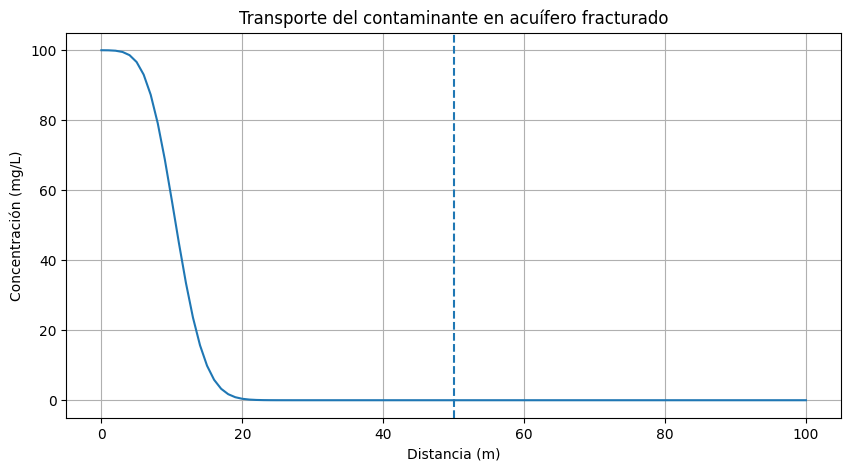

In [7]:
resultado = bohm.resolve(
    mode="1d",
    L=100,
    T=10,
    dx=1,
    dt=0.1,
    D=0.1,
    v=1,
    C0=100
)

x = resultado["x"]
C = resultado["concentration"]

print(
    f"Concentración a 50 m: "
    f"{C[50]:.2f} mg/L"
)

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    C
)

plt.axvline(
    50,
    linestyle="--"
)

plt.xlabel("Distancia (m)")
plt.ylabel("Concentración (mg/L)")
plt.title(
    "Transporte del contaminante en acuífero fracturado"
)

plt.grid()

plt.show()

In [8]:
resultado_3d = bohm.resolve(
    mode="3d",
    L=100,
    T=10,
    dx=1,
    dy=1,
    dz=1,
    dt=0.05,
    D=0.1,
    vx=1,
    vy=0.5,
    vz=0.1,
    C0=100
)

C3 = resultado_3d["C"]

x = resultado_3d["x"]
y = resultado_3d["y"]
z = resultado_3d["z"]

print("Concentración máxima:", C3.max())
print("Concentración mínima:", C3.min())

Concentración máxima: 100.0
Concentración mínima: 0.0


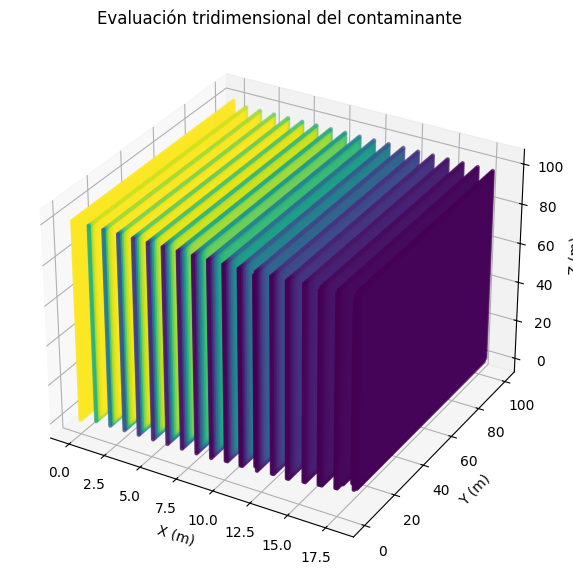

In [9]:
X, Y, Z = np.meshgrid(
    x,
    y,
    z,
    indexing="ij"
)

fig = plt.figure(
    figsize=(10, 7)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

mask = C3 > 1

ax.scatter(
    X[mask],
    Y[mask],
    Z[mask],
    c=C3[mask],
    s=5
)

ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")

plt.title(
    "Evaluación tridimensional del contaminante"
)

plt.show()

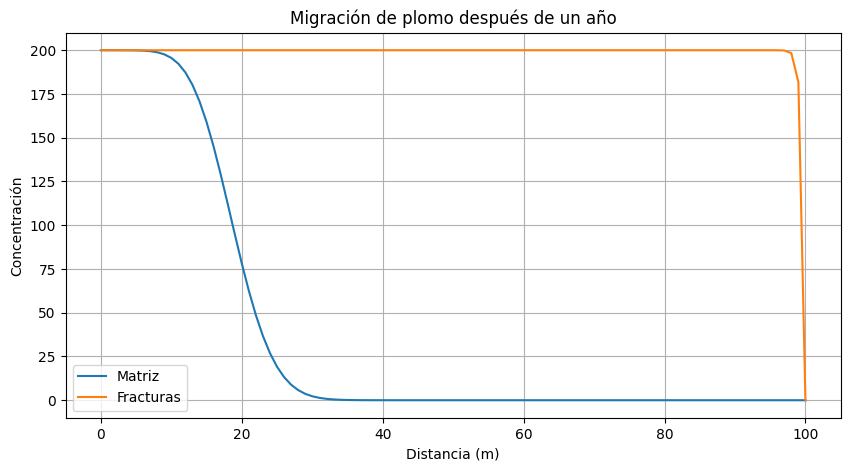

Extensión matriz: 31.0 m
Extensión fracturas: 99.0 m


In [10]:
resultado_plomo_matriz = bohm.resolve(
    mode="1d",
    L=100,
    T=365,
    dx=1,
    dt=0.1,
    D=0.005,
    v=0.05,
    C0=200
)

resultado_plomo_fractura = bohm.resolve(
    mode="1d",
    L=100,
    T=365,
    dx=1,
    dt=0.1,
    D=0.05,
    v=0.5,
    C0=200
)

x = resultado_plomo_matriz["x"]

Cm = resultado_plomo_matriz["concentration"]
Cf = resultado_plomo_fractura["concentration"]

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    Cm,
    label="Matriz"
)

plt.plot(
    x,
    Cf,
    label="Fracturas"
)

plt.xlabel("Distancia (m)")
plt.ylabel("Concentración")
plt.title(
    "Migración de plomo después de un año"
)

plt.legend()
plt.grid()

plt.show()

alcance_matriz = x[Cm > 1].max()
alcance_fractura = x[Cf > 1].max()

print(
    "Extensión matriz:",
    alcance_matriz,
    "m"
)

print(
    "Extensión fracturas:",
    alcance_fractura,
    "m"
)

Concentración a 100 m después de 30 días: 0.00 mg/L


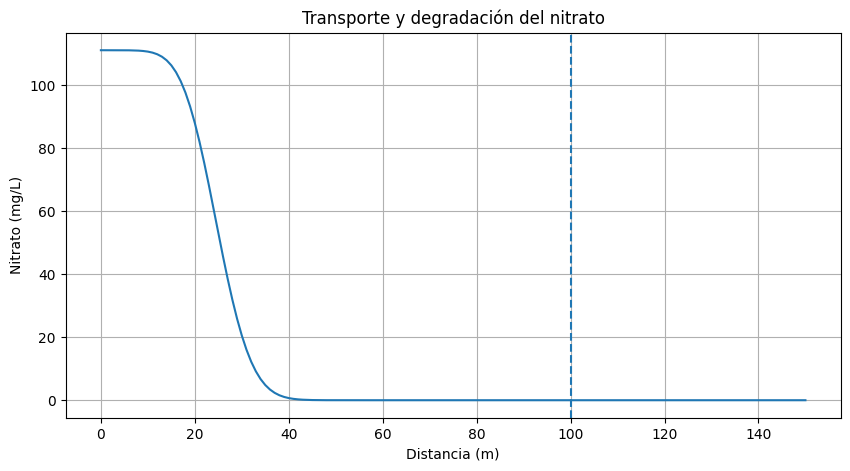

In [11]:
v_nitrato = 0.8
D_nitrato = 0.2
k_nitrato = 0.01
C0_nitrato = 150

resultado_nitrato = bohm.resolve(
    mode="1d",
    L=150,
    T=30,
    dx=1,
    dt=0.05,
    D=D_nitrato,
    v=v_nitrato,
    C0=C0_nitrato
)

x = resultado_nitrato["x"]
C = resultado_nitrato["concentration"]

C_degradada = C * np.exp(
    -k_nitrato * 30
)

indice = np.argmin(
    np.abs(x - 100)
)

print(
    "Concentración a 100 m después de 30 días:",
    f"{C_degradada[indice]:.2f} mg/L"
)

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    C_degradada
)

plt.axvline(
    100,
    linestyle="--"
)

plt.xlabel("Distancia (m)")
plt.ylabel("Nitrato (mg/L)")

plt.title(
    "Transporte y degradación del nitrato"
)

plt.grid()

plt.show()

Concentración normal a 30 m: 2.259025930921426e-31
Concentración durante lluvia a 30 m: 7.500795480259568e-19
Variación: 7.500795480257309e-19


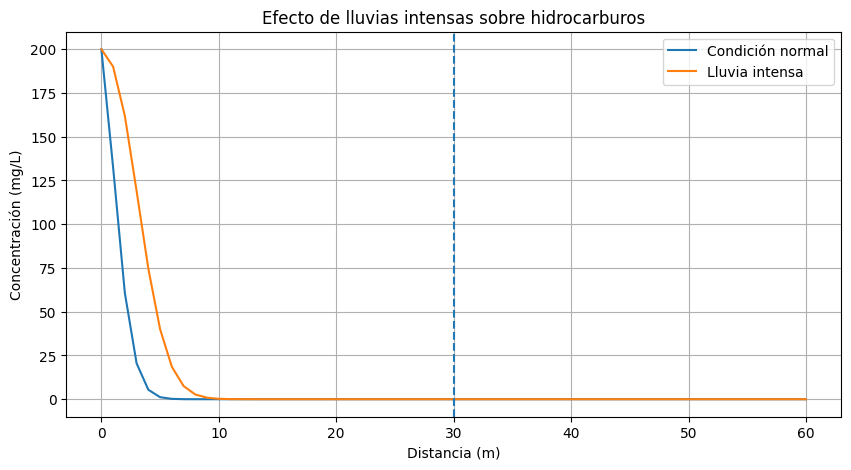

In [12]:
resultado_hidrocarburos_normal = bohm.resolve(
    mode="1d",
    L=60,
    T=5,
    dx=1,
    dt=0.05,
    D=0.03,
    v=0.2,
    C0=200
)

resultado_hidrocarburos_lluvia = bohm.resolve(
    mode="1d",
    L=60,
    T=5,
    dx=1,
    dt=0.05,
    D=0.03,
    v=0.6,
    C0=200
)

x = resultado_hidrocarburos_normal["x"]

C_normal = (
    resultado_hidrocarburos_normal[
        "concentration"
    ]
)

C_lluvia = (
    resultado_hidrocarburos_lluvia[
        "concentration"
    ]
)

indice = np.argmin(
    np.abs(x - 30)
)

print(
    "Concentración normal a 30 m:",
    C_normal[indice]
)

print(
    "Concentración durante lluvia a 30 m:",
    C_lluvia[indice]
)

print(
    "Variación:",
    C_lluvia[indice] - C_normal[indice]
)

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    C_normal,
    label="Condición normal"
)

plt.plot(
    x,
    C_lluvia,
    label="Lluvia intensa"
)

plt.axvline(
    30,
    linestyle="--"
)

plt.xlabel("Distancia (m)")
plt.ylabel("Concentración (mg/L)")

plt.title(
    "Efecto de lluvias intensas sobre hidrocarburos"
)

plt.legend()
plt.grid()

plt.show()

Concentración máxima: 500.0 mg/L


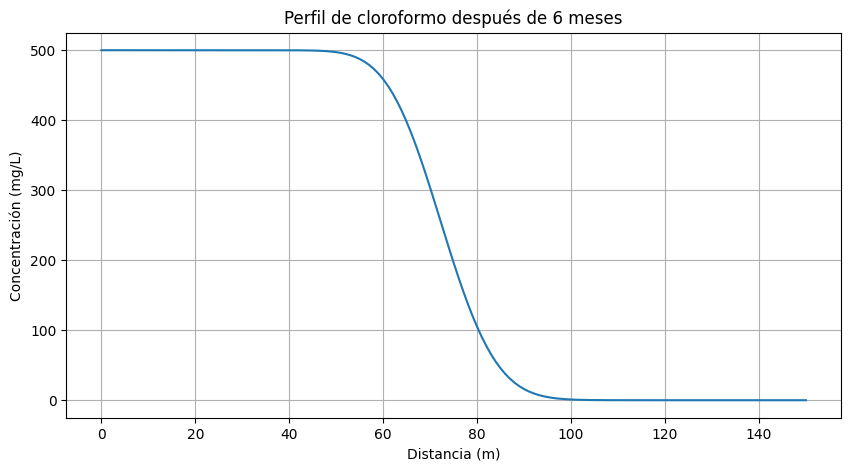

In [13]:
resultado_cloroformo = bohm.resolve(
    mode="1d",
    L=150,
    T=180,
    dx=1,
    dt=0.05,
    D=0.04,
    v=0.4,
    C0=500
)

x = resultado_cloroformo["x"]

C = resultado_cloroformo[
    "concentration"
]

print(
    "Concentración máxima:",
    C.max(),
    "mg/L"
)

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    C
)

plt.xlabel("Distancia (m)")
plt.ylabel("Concentración (mg/L)")

plt.title(
    "Perfil de cloroformo después de 6 meses"
)

plt.grid()

plt.show()